# **Suite2p ↔ pClamp/wavesurfer (.abf) alignment**
### *Neural data ↔ ball locomotion + stimulus trials (entry / presentation / exit)*

- **Section 0** — dataset + channel map + stimulus log
- **Section 1** — load suite2p, compute **dff / z-dff / deconv**
- **Section 2** — align: **peak-detected galvo frames**, **parse stimulus trials**
  (entry→presentation→exit; double-click + estimated/aborted handled), attach the
  **stimulus log**, build the **trial dict + tensor**, export **trial-info CSV**,
  and map **neurons → cortical region**

> suite2p registration + cell curation (iscell) must be done first.
> The consolidated code lives in `abf_imaging_alignment.py` in this folder.

## **Section 0 : Config**

In [1]:
import os, glob, pickle
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from abf_imaging_alignment import AlignmentSession   # same folder as this notebook

In [2]:
# ---- WHICH SESSION (the only block you normally edit) -----------------------
experimenter = "Akhil"
mouse        = "IS-2-1L"
date         = "2026-07-01"
abf_folder   = "/Volumes/Akhil Data/Akhil/RawData/IS-2-1L/wavesurfer/2026-07-01"
suite2p_path = "/Volumes/Akhil Data/Akhil/ProcessedData/IS-2-1L/2026-07-01/suite2p/plane0"  # <-- FILL IN
stim_log_csv = os.path.join(abf_folder, "logstimuli.csv")                     # stimulus log
roi_pickle   = os.path.join(os.path.dirname(suite2p_path), "..", "roi_indices_by_region.pkl")  # from Segment-ROIs notebook (optional)
save_path    = f"/Volumes/Akhil Data/Akhil/ProcessedData/{mouse}/{date}"

channels = {"galvo":6, "stim":4, "roll":0, "pitch":1, "yaw":2}   # analog-input index

# ---- parameters -------------------------------------------------------------
baseline_size      = 225      # dff baseline half-window (frames)
frame_method       = "peak"   # detect frames at the sawtooth PEAK
frames_per_tseries = 10000    # frames the scope saved per t-series (trims galvo warm-up)
frame_trim_side    = "start"  # drop leading warm-up cycles (keep last N)
long_thresh_s      = 2.0      # IN4 pulses longer than this = a PRESENTATION
n_frames_forward   = 105       # tensor window: frames FORWARD from presentation onset
pre_frames         = 15       # frames before onset (1 s pre-stim baseline at 15 Hz)

os.makedirs(save_path, exist_ok=True)
abf_paths = sorted(glob.glob(os.path.join(abf_folder, "*.abf")))
print(len(abf_paths), "abf files:", [os.path.basename(p) for p in abf_paths])
s = AlignmentSession(suite2p_path=suite2p_path, abf_paths=abf_paths, channels=channels)

3 abf files: ['sync_behavior_0000.abf', 'sync_behavior_0001.abf', 'sync_behavior_0002.abf']


## **Section 1 : DFF and Deconvolve**

In [3]:
s.load_suite2p(use_iscell=True)
# Willmore 2023 Z-scored dF/F (F-0.58*Fneu; F0/SD over whole session), plus a
# per-acquisition cubic detrend to remove photobleaching. Cache is method-aware.
s.compute_activity(cache_path=os.path.join(save_path, "all_activity_py.pkl"),
                   method="session", neuropil_coeff=0.58, detrend=True, deconvolve=True)
s.summary()

[suite2p] frames_per_folder [30000, 0, 0] degenerate; derived [10000, 10000, 10000] from filelist
[suite2p] 5352 cells x 30000 frames, fs=15.00 Hz, frames_per_folder=[10000 10000 10000]
[activity] loaded cache all_activity_py.pkl (method=session): dff (5352, 30000), deconv (5352, 30000)
acquisitions : 0
suite2p      : 5352 cells x 30000 frames @ 15.00 Hz
dff          : (5352, 30000)


#### (optional) OASIS deconvolution — needs the `oasis` package

In [4]:
# Deconvolution runs inside compute_activity (deconvolve=True) and is cached —
# nothing to do here. (Set deconvolve=False above if you do not need spikes.)

In [5]:
# all_activity_py.pkl is written by compute_activity (the cache) — nothing to save here.

## **Section 2 : Align to behavior**

**2.1 – Frames + stimulus trials.** Frames are detected at the galvo sawtooth
**peaks** and reconciled to `frames_per_tseries`. `parse_stim` builds
entry/presentation/exit trials (double-click entries kept; a missing presentation
pulse gets an onset estimated from entry + median delay). `attach_stim_log`
assigns each trial its stimulus name.

In [6]:
s.load_abf()
s.detect_frames(method=frame_method, frames_per_tseries=frames_per_tseries, trim_side=frame_trim_side)
s.detect_stim()
s.parse_stim(long_thresh_s=long_thresh_s)
s.attach_stim_log(stim_log_csv)
s.summary()
if s.stim_log_report: print("MISMATCHES:", s.stim_log_report)

[abf] sync_behavior_0000.abf: 8 ch, 10000 Hz, 711.6 s
[abf] sync_behavior_0001.abf: 8 ch, 10000 Hz, 683.7 s
[abf] sync_behavior_0002.abf: 8 ch, 10000 Hz, 684.2 s
[frames] sync_behavior_0000.abf: 10000 frames (detected 10003, trimmed 3 from start), ISI CV=0.001
[frames] sync_behavior_0001.abf: 10000 frames (detected 10003, trimmed 3 from start), ISI CV=0.001
[frames] sync_behavior_0002.abf: 10000 frames (detected 10002, trimmed 2 from start), ISI CV=0.001
[stim] sync_behavior_0000.abf: 72 raw pulses, median dur=100 ms
[stim] sync_behavior_0001.abf: 73 raw pulses, median dur=100 ms
[stim] sync_behavior_0002.abf: 72 raw pulses, median dur=99 ms
[parse] sync_behavior_0000.abf: 24 trials (24 presentations, 0 estimated, 0 aborted, 0 double-click entries)
[parse] sync_behavior_0001.abf: 24 trials (23 presentations, 1 estimated, 0 aborted, 1 double-click entries)
[parse] sync_behavior_0002.abf: 24 trials (24 presentations, 0 estimated, 0 aborted, 0 double-click entries)
[stimlog] acq0 (T-serie

**2.2 – QC:** frame peaks + trial structure (entry green, presentation blue,
estimated orange-dashed, exit red).

In [7]:
#fig,ax=plt.subplots(figsize=(12,3)); s.plot_frame_qc(acq=0, window_s=(100,101.5), ax=ax); plt.show()
#fig,ax=plt.subplots(figsize=(14,3)); s.plot_trials(acq=0, ax=ax); plt.show()

**2.3 – Validate** detected frames against suite2p `frames_per_folder`.

In [8]:
report = s.validate(cap=True, trim_side=frame_trim_side); report

[validate] frame counts consistent (per-folder)


{'detected_per_acq': [10000, 10000, 10000],
 'detected_total': 30000,
 'suite2p_total': 30000,
 'frames_per_folder': [10000, 10000, 10000],
 'messages': ['frame counts consistent (per-folder)']}

**2.4 – Trial-by-trial dict** (one entry per PRESENTATION; neural window runs
FORWARD `n_frames_forward` from the presentation-onset frame).

In [9]:
trials = s.build_trials(n_frames=n_frames_forward, pre_frames=pre_frames)
print(len(trials), "presentation trials")
pickle.dump(trials, open(os.path.join(save_path,"imaging_trials_py.pkl"),"wb"))

[trials] built 72 presentation trials (window = 15 pre + 105 forward frames)
72 presentation trials


**2.5 – Trial-info CSV.** One row per trial (`tensor_index` links each row to
the tensor); aborted trials are logged with a blank `tensor_index`.

In [10]:
trial_df = s.save_trials_csv(os.path.join(save_path,"trials_info.csv"))
trial_df.head()

[save] /Volumes/Akhil Data/Akhil/ProcessedData/IS-2-1L/2026-07-01/trials_info.csv (72 rows)


,tensor_index,acquisition,log_trial,stim,kind,present_estimated,present_onset_s,present_offset_s,present_dur_s,onset_frame,entry_onset_s,exit_onset_s,n_entry_clicks,notes
0,0,0,1,Empty,presentation,False,46.8946,54.0704,7.1758,139,44.1594,56.3719,1,NaN
1,1,0,1,3DMouse,presentation,False,80.3850,87.3473,6.9623,644,78.3104,88.9210,1,NaN
2,2,0,1,Male,presentation,False,108.4579,117.2076,8.7497,1068,105.3917,119.5816,1,NaN
3,3,0,1,Female,presentation,False,134.7357,143.5239,8.7882,1464,132.4480,145.9743,1,NaN
4,4,0,1,FamFood,presentation,False,162.7642,171.2917,8.5275,1887,160.0001,173.1132,1,NaN


**2.6 – Presentation-locked tensor** `(n_trials, n_neurons, n_frames)` with a
stimulus label per trial (`s.epoch_labels`).

In [11]:
# Build tensors for all three activity signals
# epoch returns (n_trials, n_neurons, pre_frames + n_frames_forward)
X_zdff_raw   = s.epoch("z_dff",  n_frames=n_frames_forward, pre_frames=pre_frames)
X_dff_raw    = s.epoch("dff",    n_frames=n_frames_forward, pre_frames=pre_frames)
X_deconv_raw = s.epoch("deconv", n_frames=n_frames_forward, pre_frames=pre_frames)
labels       = np.array(s.epoch_labels)

# Per-trial baseline correction: subtract mean of the pre_frames window.
# Keep the full trace (pre + post) so baseline period is available for plotting.
def baseline_correct(X, n_pre):
    bl = X[:, :, :n_pre].mean(axis=2, keepdims=True)  # (trials, neurons, 1)
    return X - bl

X_zdff   = baseline_correct(X_zdff_raw,   pre_frames)
X_dff    = baseline_correct(X_dff_raw,    pre_frames)
X_deconv = baseline_correct(X_deconv_raw, pre_frames)

print("z_dff tensor:", X_zdff.shape, f"  (first {pre_frames} frames = baseline)")
print("dff tensor:  ", X_dff.shape)
print("deconv tensor:", X_deconv.shape)
print("stimuli:", sorted(set(labels)))

np.save(os.path.join(save_path, "tensor_zdff.npy"),   X_zdff)
np.save(os.path.join(save_path, "tensor_dff.npy"),    X_dff)
np.save(os.path.join(save_path, "tensor_deconv.npy"), X_deconv)
np.save(os.path.join(save_path, "tensor_labels.npy"), labels)

z_dff tensor: (72, 5352, 120)   (first 15 frames = baseline)
dff tensor:   (72, 5352, 120)
deconv tensor: (72, 5352, 120)
stimuli: ['3DMouse', 'Empty', 'FamFood', 'Female', 'Male', 'NewFood']


In [12]:
# Save session-length ball signals (aligned to imaging frames) for kinematics regression
ball = s.ball_session()
np.savez(os.path.join(save_path, "ball_session.npz"), **ball)
print("ball signals:", {k: v.shape for k, v in ball.items()})

# Save session-level continuous signals for kinematics regression
np.save(os.path.join(save_path, "session_zdff.npy"), s.z_dff)
np.save(os.path.join(save_path, "session_dff.npy"), s.dff)
print("session z_dff:", s.z_dff.shape, "| dff:", s.dff.shape)

ball signals: {'roll': (30000,), 'pitch': (30000,), 'yaw': (30000,)}
session z_dff: (5352, 30000) | dff: (5352, 30000)


**2.7 – Map neurons → cortical region** (from the *Segment ROIs by Anatomical
Region* notebook). `regions` is aligned to the tensor's neuron axis.

In [13]:
try:
    roi_dict = pickle.load(open(os.path.abspath(roi_pickle), "rb"))
    regions = s.neuron_regions(roi_dict, s.suite2p["cell_idx"])
    np.save(os.path.join(save_path,"neuron_regions.npy"), regions)
    print({r:int((regions==r).sum()) for r in sorted(set(regions))})
    # e.g. slice the tensor by area:  X_v1 = X[:, regions=="V1", :]
except FileNotFoundError:
    print("roi_indices_by_region.pkl not found — run the Segment-ROIs notebook first")

{'AM': 716, 'PM': 591, 'PPC': 1248, 'RL': 493, 'RSC': 250, 'SMc': 315, 'V1': 1737, 'none': 2}


**2.8 – Quick sanity: mean response per stimulus**

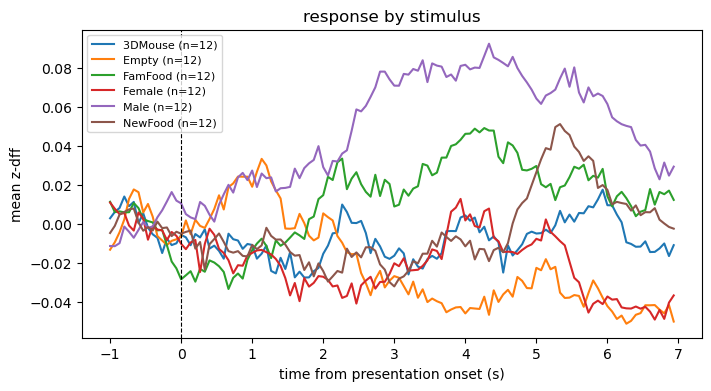

In [14]:
fig, ax = plt.subplots(figsize=(8,4))
fs = s.suite2p["fs"]
t = (np.arange(pre_frames + n_frames_forward) - pre_frames) / fs  # negative = baseline
for stim in sorted(set(labels)):
    m = np.nanmean(X_zdff[labels==stim], axis=(0,1))
    ax.plot(t, m, label=f"{stim} (n={np.sum(labels==stim)})")
ax.axvline(0, color="k", ls="--", lw=0.8)
ax.set(xlabel="time from presentation onset (s)", ylabel="mean z-dff", title="response by stimulus")
ax.legend(fontsize=8); plt.show()